In [1]:

import json
import os
from pathlib import Path
from collections import Counter

import cv2
import numpy as np

ANNOTATIONS_PATH = "/kaggle/input/datasets/ishanabharathi/solarfila/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"
IMAGES_DIR = "/kaggle/input/datasets/ishanabharathi/solarfila/MAGFiLO_1.0_Kaggle_2026/train/train_images"

# ============================================================
# 1. LOAD AND INSPECT THE RAW JSON STRUCTURE
# ============================================================
with open(ANNOTATIONS_PATH) as f:
    coco = json.load(f)

print("=" * 60)
print("TOP-LEVEL KEYS IN THE JSON")
print("=" * 60)
print(list(coco.keys()))
print()

print("=" * 60)
print("ONE RAW EXAMPLE OF EACH KEY (to see the actual structure)")
print("=" * 60)
for key in coco.keys():
    val = coco[key]
    if isinstance(val, list) and len(val) > 0:
        print(f"--- coco['{key}'][0] ---")
        print(json.dumps(val[0], indent=2)[:800])
        print()
    else:
        print(f"--- coco['{key}'] ---")
        print(str(val)[:300])
        print()

# ============================================================
# 2. IMAGE-LEVEL STATS
# ============================================================
print("=" * 60)
print("IMAGES")
print("=" * 60)
print(f"Number of images: {len(coco['images'])}")

sizes = Counter((im["width"], im["height"]) for im in coco["images"])
print("Image sizes found (size: count):")
for size, count in sizes.most_common():
    print(f"  {size}: {count}")
print()

# ============================================================
# 3. CATEGORY / CLASS INFO
# ============================================================
if "categories" in coco:
    print("=" * 60)
    print("CATEGORIES")
    print("=" * 60)
    for cat in coco["categories"]:
        print(f"  id={cat.get('id')}  name={cat.get('name')}")
    print()

# ============================================================
# 4. ANNOTATION-LEVEL STATS
# ============================================================
print("=" * 60)
print("ANNOTATIONS")
print("=" * 60)
anns = coco["annotations"]
print(f"Total annotation count: {len(anns)}")

imgs_per_ann_count = Counter(a["image_id"] for a in anns)
counts_per_image = list(imgs_per_ann_count.values())
print(f"Filaments per image -- min: {min(counts_per_image)}, "
      f"median: {np.median(counts_per_image):.1f}, "
      f"max: {max(counts_per_image)}, "
      f"mean: {np.mean(counts_per_image):.1f}")
print()

# does every annotation have a segmentation (mask), not just a bbox?
has_seg = sum(1 for a in anns if a.get("segmentation"))
print(f"Annotations with a segmentation field: {has_seg} / {len(anns)}")

# is segmentation polygon or RLE?
sample_seg = anns[0].get("segmentation")
print(f"Segmentation format of first annotation: {type(sample_seg)}")
if isinstance(sample_seg, dict):
    print(f"  keys: {list(sample_seg.keys())}")
elif isinstance(sample_seg, list):
    print(f"  looks like polygon points, length: {len(sample_seg)}")
print()

# ============================================================
# 5. AREA + SHAPE STATS (what we need for tuning thresholds)
# ============================================================
areas = np.array([a["area"] for a in anns])
bboxes = np.array([a["bbox"] for a in anns])  # [x, y, w, h]
widths, heights = bboxes[:, 2], bboxes[:, 3]
aspect_ratios = np.maximum(widths, heights) / np.maximum(1.0, np.minimum(widths, heights))

print("=" * 60)
print("FILAMENT SIZE / SHAPE STATS")
print("=" * 60)
for label, arr in [("area (px)", areas), ("bbox width", widths),
                    ("bbox height", heights), ("aspect ratio", aspect_ratios)]:
    print(f"{label:15s}  min={arr.min():.1f}  p5={np.percentile(arr,5):.1f}  "
          f"median={np.median(arr):.1f}  p95={np.percentile(arr,95):.1f}  max={arr.max():.1f}")
print()

# ============================================================
# 6. ACTUAL PIXEL VALUE STATS (for the thresholding step)
# ============================================================
print("=" * 60)
print("SAMPLE IMAGE PIXEL STATS (first 5 images)")
print("=" * 60)
for im_info in coco["images"][:5]:
    path = os.path.join(IMAGES_DIR, im_info["file_name"])
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if gray is None:
        print(f"  {im_info['file_name']}: COULD NOT LOAD -- check IMAGES_DIR path")
        continue
    print(f"  {im_info['file_name']}: shape={gray.shape}  "
          f"min={gray.min()} max={gray.max()} mean={gray.mean():.1f}")
print()

print("=" * 60)
print("DONE -- paste everything above back into chat")
print("=" * 60)

TOP-LEVEL KEYS IN THE JSON
['info', 'licenses', 'categories', 'images', 'annotations']

ONE RAW EXAMPLE OF EACH KEY (to see the actual structure)
--- coco['info'] ---
{'description': 'MLEcoFi 2024 Dataset - V1.0', 'url': 'https://www.mlecofi.net/', 'version': '1.0', 'year': 2024, 'contributor': 'MLEcoFi Team', 'date_created': '2024-07-15', 'team': 'Earth-Space AI Research Lab (www.esairlab.com)', 'collaborators': ['National Solar Observatory, Georgia State Univer

--- coco['licenses'] ---
{'url': 'https://gong.nso.edu/', 'id': 1, 'name': 'NSO/GONG'}

--- coco['categories'][0] ---
{
  "supercategory": "filament",
  "id": 1,
  "name": "Left"
}

--- coco['images'][0] ---
{
  "license": 1,
  "file_name": "20140609195854Bh.jpeg",
  "url": "https://gong2.nso.edu/HA/hag/201406/20140609/20140609195854Bh.jpg",
  "height": 2048,
  "width": 2048,
  "date_captured": "2014-06-09 19:58:54",
  "id": "040301-20140609195854Bh"
}

--- coco['annotations'][0] ---
{
  "segmentation": [
    [
      480.9382

INSTALLING DEPENDENCIES
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 52.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 kB 7.3 MB/s eta 0:00:00
✅ Dependencies ready
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

SYSTEM
Device : cuda
GPUs   : 2

DATASET PATHS
TRAIN JSON   : /kaggle/input/datasets/ishanabharathi/solarfila/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
TRAIN IMAGES : /kaggle/input/datasets/ishanabharathi/solarfila/MAGFiLO_1.0_Kaggle_2026/train/train_images
TEST IMAGES  : /kaggle/input/datasets/ishanabharathi/

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

No usable refiner checkpoint.
Training refiner...


Refiner train 1:   0%|          | 0/867 [00:00<?, ?it/s]

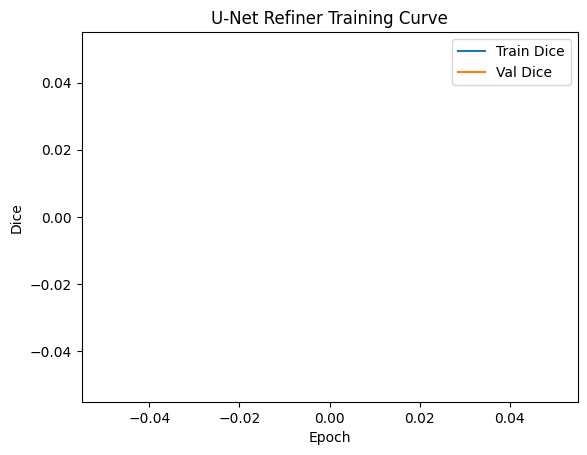

Refiner val 1:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 01/12 | train loss=0.2542 dice=0.7413 | val loss=0.1700 dice=0.7771
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 2:   0%|          | 0/867 [00:00<?, ?it/s]

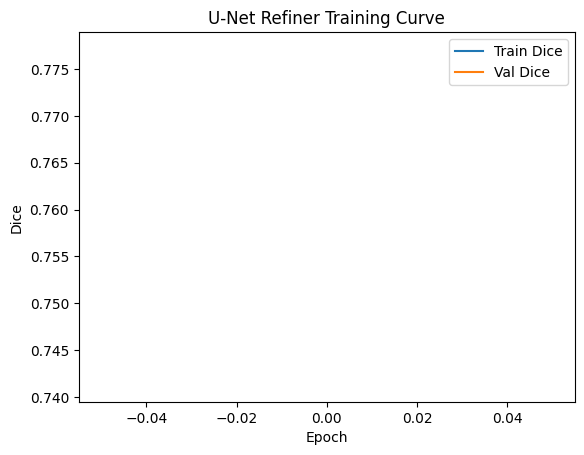

Refiner val 2:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 02/12 | train loss=0.1587 dice=0.7901 | val loss=0.1520 dice=0.7984
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 3:   0%|          | 0/867 [00:00<?, ?it/s]

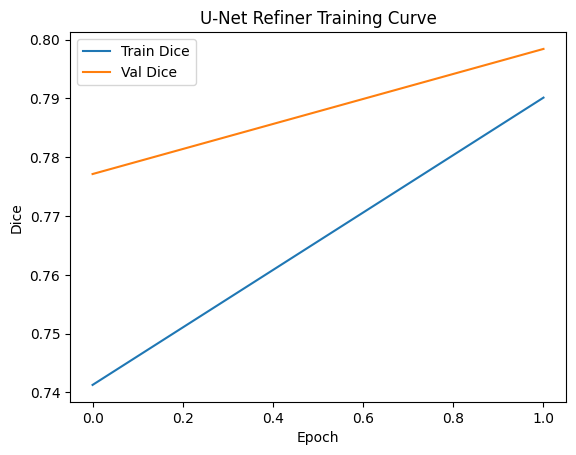

Refiner val 3:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 03/12 | train loss=0.1529 dice=0.7964 | val loss=0.1484 dice=0.8021
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 4:   0%|          | 0/867 [00:00<?, ?it/s]

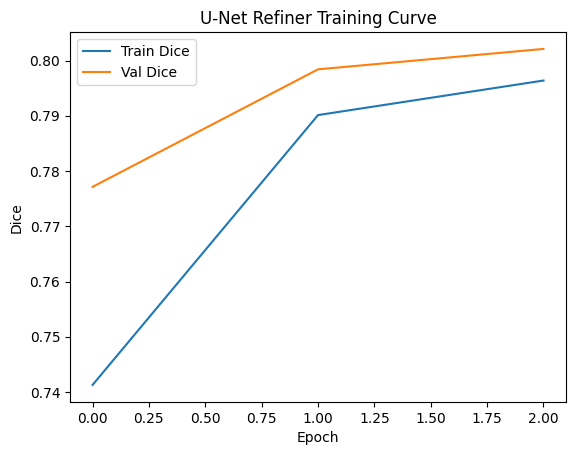

Refiner val 4:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 04/12 | train loss=0.1481 dice=0.8023 | val loss=0.1453 dice=0.8064
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 5:   0%|          | 0/867 [00:00<?, ?it/s]

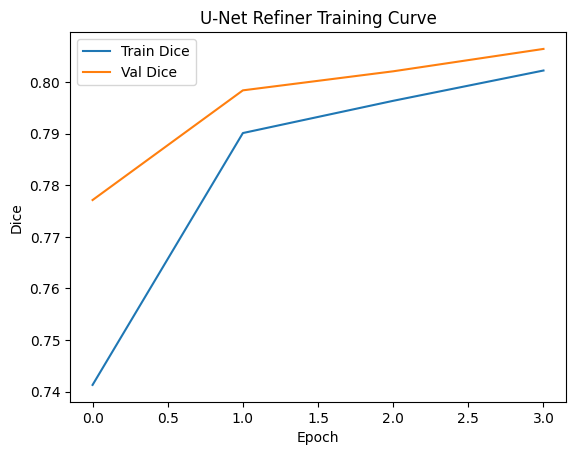

Refiner val 5:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 05/12 | train loss=0.1446 dice=0.8065 | val loss=0.1429 dice=0.8091
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 6:   0%|          | 0/867 [00:00<?, ?it/s]

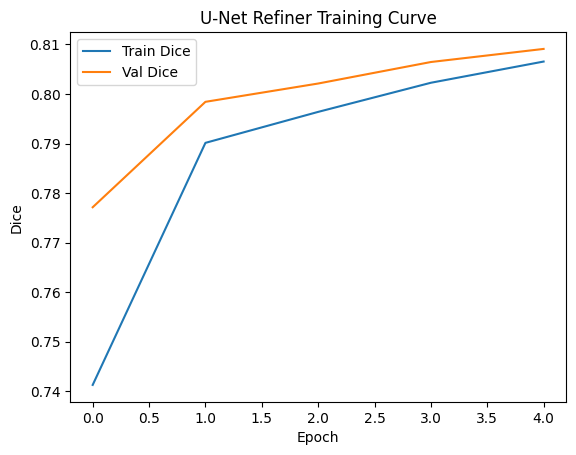

Refiner val 6:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 06/12 | train loss=0.1422 dice=0.8095 | val loss=0.1416 dice=0.8105
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 7:   0%|          | 0/867 [00:00<?, ?it/s]

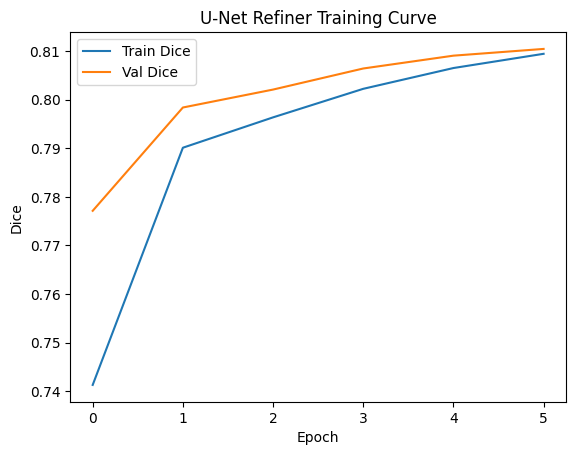

Refiner val 7:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 07/12 | train loss=0.1394 dice=0.8132 | val loss=0.1369 dice=0.8171
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 8:   0%|          | 0/867 [00:00<?, ?it/s]

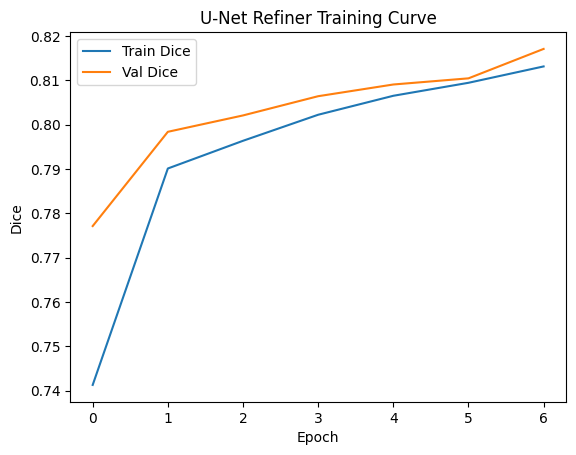

Refiner val 8:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 08/12 | train loss=0.1363 dice=0.8172 | val loss=0.1356 dice=0.8181
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 9:   0%|          | 0/867 [00:00<?, ?it/s]

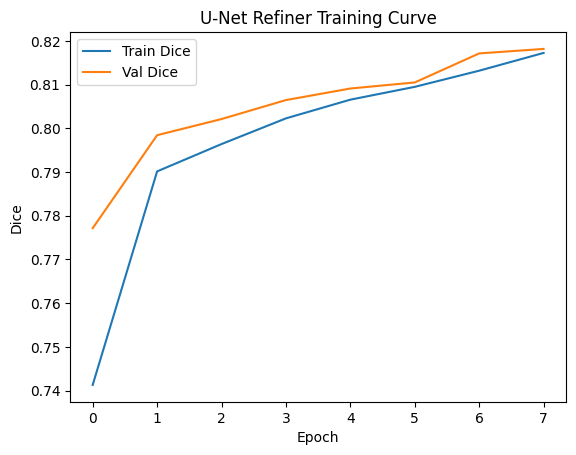

Refiner val 9:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 09/12 | train loss=0.1340 dice=0.8200 | val loss=0.1342 dice=0.8205
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 10:   0%|          | 0/867 [00:00<?, ?it/s]

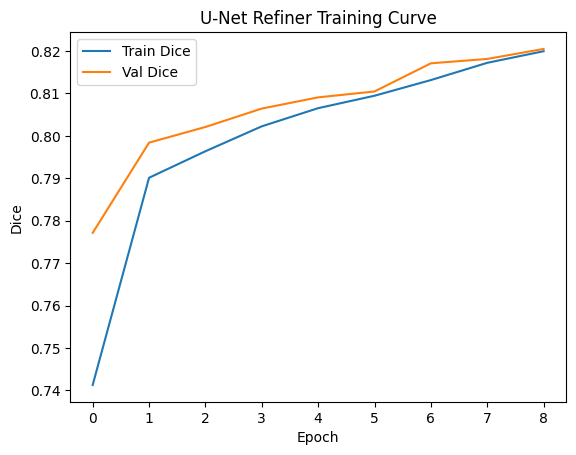

Refiner val 10:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 10/12 | train loss=0.1316 dice=0.8233 | val loss=0.1335 dice=0.8211
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 11:   0%|          | 0/867 [00:00<?, ?it/s]

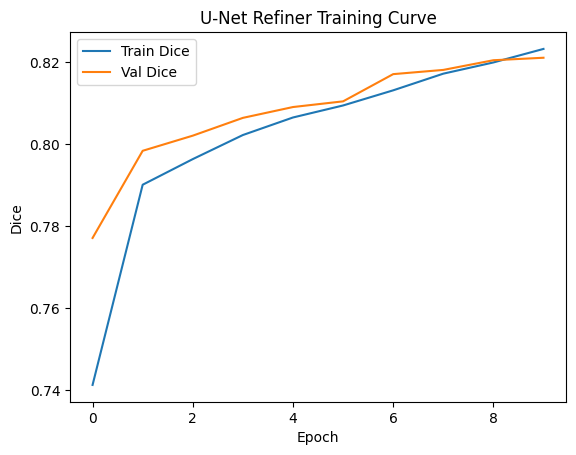

Refiner val 11:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 11/12 | train loss=0.1302 dice=0.8250 | val loss=0.1326 dice=0.8223
✅ Saved: /kaggle/working/seed_refiner_best.pt


Refiner train 12:   0%|          | 0/867 [00:00<?, ?it/s]

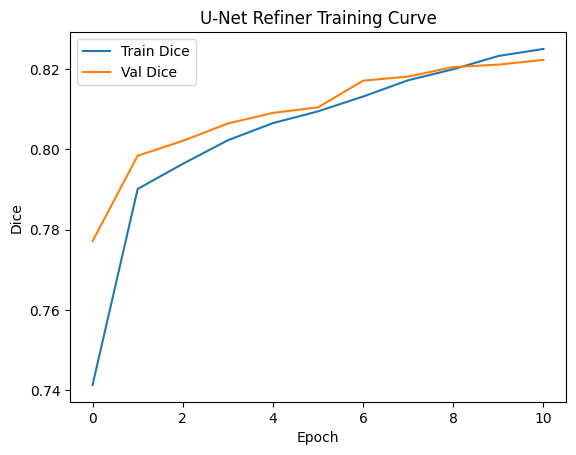

Refiner val 12:   0%|          | 0/79 [00:00<?, ?it/s]

Epoch 12/12 | train loss=0.1292 dice=0.8263 | val loss=0.1325 dice=0.8223
✅ Refiner ready

TEST SET
Test images: 180


In [2]:
# ============================================================
# MAGFiLO SOLAR FILAMENT SEGMENTATION
# SINGLE-CELL COMPETITION PIPELINE
#
# Output:
#   /kaggle/working/submission.csv
#
# Pipeline:
#   COCO annotations
#        ↓
#   YOLO detector
#        ↓
#   Seed generation
#        ↓
#   U-Net refinement
#        ↓
#   RLE segmentation
#        ↓
#   submission.csv
#
# The code automatically searches /kaggle/input instead of
# assuming a fixed Kaggle dataset path.
# ============================================================

import sys
import subprocess
import os
import json
import random
import shutil
import math
import warnings
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ============================================================
# 1. INSTALL DEPENDENCIES
# ============================================================

print("=" * 70)
print("INSTALLING DEPENDENCIES")
print("=" * 70)

packages = [
    "segmentation-models-pytorch",
    "albumentations",
    "pycocotools",
    "ultralytics"
]

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    *packages
])

print("✅ Dependencies ready")


# ============================================================
# 2. IMPORTS
# ============================================================

import cv2
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp

from tqdm.auto import tqdm

from pycocotools import mask as mask_utils

from ultralytics import YOLO


# ============================================================
# 3. GLOBAL CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

N_GPUS = (
    torch.cuda.device_count()
    if torch.cuda.is_available()
    else 0
)

WORKERS = 2

OUT_DIR = Path("/kaggle/working")

print()
print("=" * 70)
print("SYSTEM")
print("=" * 70)

print("Device :", DEVICE)
print("GPUs   :", N_GPUS)


# ============================================================
# 4. COMPETITION PARAMETERS
# ============================================================

YOLO_MODEL = "yolo11s.pt"

YOLO_IMGSZ = 1280

YOLO_EPOCHS = 40

YOLO_BATCH = 8

YOLO_CONF = 0.28

YOLO_IOU = 0.50

REFINE_CROP = 512

REFINE_EPOCHS = 12

REFINE_BATCH = 8

REFINE_LR = 3e-4

REFINE_THR = 0.50

VAL_FRAC = 0.15

PAD_RATIO = 0.40

CONTEXT = 1.5

MIN_CROP = 96

MIN_AREA = 200

USE_TTA = False

USE_BOX_JITTER_TTA = False

BOX_JITTER_PX = 8

MAX_TEST_IMAGES = None


# ============================================================
# IMPORTANT:
# Set these according to whether your trained models exist.
#
# True  = use existing trained checkpoint
# False = train model if checkpoint isn't found
# ============================================================

SKIP_YOLO_TRAIN = True

SKIP_REFINER_TRAIN = False


# ============================================================
# 5. FIXED KAGGLE DATASET PATHS
# ============================================================

# ------------------------------------------------------------
# TRAIN ANNOTATIONS
# ------------------------------------------------------------

TRAIN_JSON = Path(
    "/kaggle/input/datasets/ishanabharathi/solarfila/"
    "MAGFiLO_1.0_Kaggle_2026/train/"
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)


# ------------------------------------------------------------
# TRAIN IMAGES
# ------------------------------------------------------------

TRAIN_IMAGES = Path(
    "/kaggle/input/datasets/ishanabharathi/solarfila/"
    "MAGFiLO_1.0_Kaggle_2026/train/"
    "train_images"
)


# ------------------------------------------------------------
# TEST IMAGES
# ------------------------------------------------------------

TEST_IMAGES = Path(
    "/kaggle/input/datasets/ishanabharathi/solarfila/"
    "MAGFiLO_1.0_Kaggle_2026/test/"
    "test_images"
)


# ============================================================
# CHECK PATHS
# ============================================================

print()
print("=" * 70)
print("DATASET PATHS")
print("=" * 70)

print("TRAIN JSON   :", TRAIN_JSON)
print("TRAIN IMAGES :", TRAIN_IMAGES)
print("TEST IMAGES  :", TEST_IMAGES)


if not TRAIN_JSON.exists():

    raise FileNotFoundError(
        f"\n❌ Training annotation file not found:\n"
        f"{TRAIN_JSON}"
    )


if not TRAIN_IMAGES.exists():

    raise FileNotFoundError(
        f"\n❌ Training image directory not found:\n"
        f"{TRAIN_IMAGES}"
    )


if not TEST_IMAGES.exists():

    raise FileNotFoundError(
        f"\n❌ Test image directory not found:\n"
        f"{TEST_IMAGES}"
    )


# ============================================================
# COUNT IMAGES
# ============================================================

train_image_files = [
    p
    for p in TRAIN_IMAGES.iterdir()
    if p.is_file()
    and p.suffix.lower()
    in {
        ".jpg",
        ".jpeg",
        ".png"
    }
]


test_image_files = [
    p
    for p in TEST_IMAGES.iterdir()
    if p.is_file()
    and p.suffix.lower()
    in {
        ".jpg",
        ".jpeg",
        ".png"
    }
]


print()
print("Training images:", len(train_image_files))
print("Test images    :", len(test_image_files))

print()
print("✅ All dataset paths are valid")

# ============================================================
# FIND REFINER CHECKPOINT
# ============================================================
REFINER_CKPT = None

for p in Path("/kaggle/input").rglob("*.pt"):
    name = p.name.lower()
    if "refiner" in name and "best" in name:
        REFINER_CKPT = p
        break

if REFINER_CKPT is None:
    for p in Path("/kaggle/input").rglob("*.pt"):
        if "refiner" in p.name.lower():
            REFINER_CKPT = p
            break

print("Refiner checkpoint:", REFINER_CKPT)

if REFINER_CKPT is None:
    print("No existing checkpoint found — will train the refiner from scratch.")
# ============================================================
# 10. OUTPUT FILES
# ============================================================

YOLO_DATA = OUT_DIR / "yolo_detect_data"

YOLO_RUNS = OUT_DIR / "ultralytics_runs"

SUBMISSION_CSV = OUT_DIR / "submission.csv"

PRED_VAL_CSV = OUT_DIR / "pred_val.csv"

GT_VAL_CSV = OUT_DIR / "gt_val.csv"


# ============================================================
# 11. LOAD COCO
# ============================================================

print()
print("=" * 70)
print("LOADING COCO DATASET")
print("=" * 70)


with open(TRAIN_JSON, "r") as f:

    coco = json.load(f)


images_by_id = {
    im["id"]: im
    for im in coco["images"]
}


anns_by_image = defaultdict(list)


for ann in coco["annotations"]:

    anns_by_image[
        ann["image_id"]
    ].append(ann)


print(
    "COCO images:",
    len(coco["images"])
)

print(
    "COCO annotations:",
    len(coco["annotations"])
)


# ============================================================
# 12. BUILD SAMPLES
# ============================================================

samples = []

missing = 0


# Build a filename lookup for robustness
train_files = {}

for p in TRAIN_IMAGES.iterdir():

    if (
        p.is_file()
        and p.suffix.lower()
        in {".jpg", ".jpeg", ".png"}
    ):

        train_files[p.name] = p


for image_id, im in images_by_id.items():

    filename = im["file_name"]

    path = TRAIN_IMAGES / filename


    if not path.exists():

        # filename-only search
        if filename in train_files:

            path = train_files[filename]

        else:

            # stem-based fallback
            stem = Path(filename).stem

            matches = [
                p
                for name, p in train_files.items()
                if Path(name).stem == stem
            ]

            if matches:

                path = matches[0]

            else:

                missing += 1

                continue


    samples.append({

        "image_id": image_id,

        "file_name": filename,

        "path": path,

        "stem": path.stem,

        "height": int(
            im.get("height", 2048)
        ),

        "width": int(
            im.get("width", 2048)
        ),

        "annotations":
            anns_by_image[image_id]

    })


print()
print(
    "Usable training samples:",
    len(samples)
)

print(
    "Missing images:",
    missing
)


if len(samples) == 0:

    raise RuntimeError(
        "❌ Zero training images matched COCO annotations."
    )


# ============================================================
# 13. TRAIN / VALIDATION SPLIT
# ============================================================

stems = sorted({
    s["stem"]
    for s in samples
})


random.Random(SEED).shuffle(stems)


n_val = max(
    1,
    int(len(stems) * VAL_FRAC)
)


val_stem_list = stems[:n_val]

train_stem_list = stems[n_val:]


val_stems = set(val_stem_list)

train_stems = set(train_stem_list)


train_samples = [
    s
    for s in samples
    if s["stem"] in train_stems
]


val_samples = [
    s
    for s in samples
    if s["stem"] in val_stems
]


print()
print(
    "Train images:",
    len(train_samples)
)

print(
    "Validation images:",
    len(val_samples)
)


# ============================================================
# 14. ANNOTATION LIST
# ============================================================

def build_ann_list(sample_list):

    rows = []

    for s in sample_list:

        for ann in s["annotations"]:

            if ann.get("iscrowd", 0):
                continue

            if (
                not ann.get("segmentation")
                and not ann.get("bbox")
            ):
                continue

            rows.append(
                (s, ann)
            )

    return rows


train_ann_list = build_ann_list(
    train_samples
)

val_ann_list = build_ann_list(
    val_samples
)


print(
    "Train annotations:",
    len(train_ann_list)
)

print(
    "Val annotations:",
    len(val_ann_list)
)


# ============================================================
# 15. BUILD YOLO DATASET
# ============================================================



# ============================================================
# 18. MASK UTILITIES
# ============================================================

def ann_to_mask(
    ann,
    h,
    w
):

    segmentation = ann.get(
        "segmentation"
    )


    if segmentation:

        try:

            rles = (
                mask_utils.frPyObjects(
                    segmentation,
                    h,
                    w
                )
            )


            rle = (
                mask_utils.merge(rles)
                if isinstance(rles, list)
                else rles
            )


            mask = mask_utils.decode(
                rle
            )


            if mask.ndim == 3:

                mask = np.any(
                    mask,
                    axis=2
                )


            return mask.astype(
                np.uint8
            )

        except Exception:
            pass


    # bbox fallback
    x, y, bw, bh = map(
        int,
        ann["bbox"]
    )


    x = max(
        0,
        min(x, w - 1)
    )

    y = max(
        0,
        min(y, h - 1)
    )

    x2 = min(
        w,
        x + max(1, bw)
    )

    y2 = min(
        h,
        y + max(1, bh)
    )


    mask = np.zeros(
        (h, w),
        dtype=np.uint8
    )


    mask[y:y2, x:x2] = 1


    return mask


# ============================================================
# 19. CROP UTILITIES
# ============================================================

def square_bounds_from_bbox(
    bbox,
    h,
    w,
    context=CONTEXT,
    minimum=MIN_CROP
):

    x, y, bw, bh = bbox


    cx = x + bw / 2

    cy = y + bh / 2


    side = int(
        math.ceil(
            max(bw, bh)
            * context
        )
    )


    side = max(
        side,
        minimum
    )


    # do not exceed image dimensions
    side = min(
        side,
        h,
        w
    )


    x0 = int(
        round(
            cx - side / 2
        )
    )

    y0 = int(
        round(
            cy - side / 2
        )
    )


    x1 = x0 + side

    y1 = y0 + side


    if x0 < 0:

        x1 -= x0

        x0 = 0


    if y0 < 0:

        y1 -= y0

        y0 = 0


    if x1 > w:

        shift = x1 - w

        x0 -= shift

        x1 = w


    if y1 > h:

        shift = y1 - h

        y0 -= shift

        y1 = h


    x0 = max(
        0,
        x0
    )

    y0 = max(
        0,
        y0
    )

    x1 = min(
        w,
        x1
    )

    y1 = min(
        h,
        y1
    )


    return (
        x0,
        y0,
        x1,
        y1
    )


# ============================================================
# 20. SEED GENERATION
# ============================================================

def seed_from_box(
    h,
    w,
    bbox,
    pad_ratio=PAD_RATIO
):

    x, y, bw, bh = bbox


    px = bw * pad_ratio

    py = bh * pad_ratio


    x0 = max(
        0,
        int(x - px)
    )

    y0 = max(
        0,
        int(y - py)
    )


    x1 = min(
        w,
        int(x + bw + px)
    )

    y1 = min(
        h,
        int(y + bh + py)
    )


    seed = np.zeros(
        (h, w),
        dtype=np.uint8
    )


    seed[y0:y1, x0:x1] = 1


    return seed


# ============================================================
# 21. BOX JITTER
# ============================================================

def jitter_bbox(
    bbox,
    h,
    w,
    rng
):

    x, y, bw, bh = map(
        float,
        bbox
    )


    x += float(
        rng.uniform(
            -0.15,
            0.15
        ) * bw
    )


    y += float(
        rng.uniform(
            -0.15,
            0.15
        ) * bh
    )


    sx = float(
        rng.uniform(
            0.85,
            1.25
        )
    )


    sy = float(
        rng.uniform(
            0.85,
            1.25
        )
    )


    cx = x + bw / 2

    cy = y + bh / 2


    bw = max(
        8.0,
        bw * sx
    )

    bh = max(
        8.0,
        bh * sy
    )


    x = cx - bw / 2

    y = cy - bh / 2


    x = float(
        np.clip(
            x,
            0,
            max(0, w - 2)
        )
    )

    y = float(
        np.clip(
            y,
            0,
            max(0, h - 2)
        )
    )


    bw = float(
        min(
            bw,
            w - x
        )
    )

    bh = float(
        min(
            bh,
            h - y
        )
    )


    pad = float(
        rng.uniform(
            PAD_RATIO * 0.5,
            PAD_RATIO * 1.5
        )
    )


    return [
        x,
        y,
        bw,
        bh
    ], pad


# ============================================================
# 22. REFINER DATASET
# ============================================================

class SeedRefineDataset(
    Dataset
):

    def __init__(
        self,
        ann_list,
        crop_size,
        augment=False
    ):

        self.ann_list = ann_list

        self.crop_size = crop_size

        self.augment = augment

        self.cache = {}


    def __len__(self):

        return len(
            self.ann_list
        )


    def load_image(
        self,
        path
    ):

        key = str(path)


        if key not in self.cache:

            img = cv2.imread(
                key,
                cv2.IMREAD_GRAYSCALE
            )


            if img is None:

                raise FileNotFoundError(
                    key
                )


            self.cache[key] = img


        return self.cache[key]


    def __getitem__(
        self,
        idx
    ):

        sample, ann = (
            self.ann_list[idx]
        )


        img = self.load_image(
            sample["path"]
        )


        h, w = img.shape


        target = ann_to_mask(
            ann,
            h,
            w
        )


        gt_bbox = ann["bbox"]


        if self.augment:

            rng = np.random.default_rng(
                SEED
                + idx
                + random.randint(
                    0,
                    10000
                )
            )


            box_j, pad_j = jitter_bbox(
                gt_bbox,
                h,
                w,
                rng
            )


            seed_full = seed_from_box(
                h,
                w,
                box_j,
                pad_ratio=pad_j
            )

        else:

            seed_full = seed_from_box(
                h,
                w,
                gt_bbox
            )


        x0, y0, x1, y1 = (
            square_bounds_from_bbox(
                gt_bbox,
                h,
                w
            )
        )


        crop = img[
            y0:y1,
            x0:x1
        ]


        target_crop = target[
            y0:y1,
            x0:x1
        ]


        seed_crop = seed_full[
            y0:y1,
            x0:x1
        ]


        img_c = cv2.resize(
            crop,
            (
                self.crop_size,
                self.crop_size
            ),
            interpolation=cv2.INTER_LINEAR
        )


        tgt_c = cv2.resize(
            target_crop,
            (
                self.crop_size,
                self.crop_size
            ),
            interpolation=cv2.INTER_NEAREST
        )


        seed_c = cv2.resize(
            seed_crop,
            (
                self.crop_size,
                self.crop_size
            ),
            interpolation=cv2.INTER_NEAREST
        )


        # CLAHE improves faint filament contrast
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        ).apply(img_c)


        # augmentation
        if (
            self.augment
            and random.random() < 0.5
        ):

            img_c = np.fliplr(
                img_c
            ).copy()

            clahe = np.fliplr(
                clahe
            ).copy()

            tgt_c = np.fliplr(
                tgt_c
            ).copy()

            seed_c = np.fliplr(
                seed_c
            ).copy()


        if (
            self.augment
            and random.random() < 0.5
        ):

            img_c = np.flipud(
                img_c
            ).copy()

            clahe = np.flipud(
                clahe
            ).copy()

            tgt_c = np.flipud(
                tgt_c
            ).copy()

            seed_c = np.flipud(
                seed_c
            ).copy()


        x = np.stack(
            [
                img_c,
                clahe,
                seed_c * 255
            ],
            axis=0
        ).astype(
            np.float32
        ) / 255.0


        mean = np.array(
            [
                0.485,
                0.456,
                0.406
            ],
            dtype=np.float32
        )[:, None, None]


        std = np.array(
            [
                0.229,
                0.224,
                0.225
            ],
            dtype=np.float32
        )[:, None, None]


        x = (
            x - mean
        ) / std


        y = torch.from_numpy(
            tgt_c.astype(
                np.float32
            )
        )[None]


        return (
            torch.from_numpy(x),
            y
        )


# ============================================================
# 23. CREATE REFINER DATALOADERS
# ============================================================

train_ds = SeedRefineDataset(
    train_ann_list,
    REFINE_CROP,
    augment=True
)

val_ds = SeedRefineDataset(
    val_ann_list,
    REFINE_CROP,
    augment=False
)


train_loader = DataLoader(
    train_ds,
    batch_size=REFINE_BATCH,
    shuffle=True,
    num_workers=WORKERS,
    pin_memory=True,
    drop_last=(
        len(train_ds) >= REFINE_BATCH
    )
)


val_loader = DataLoader(
    val_ds,
    batch_size=REFINE_BATCH * 2,
    shuffle=False,
    num_workers=WORKERS,
    pin_memory=True
)


print()
print(
    "Refiner train samples:",
    len(train_ds)
)

print(
    "Refiner val samples:",
    len(val_ds)
)


# ============================================================
# 24. LOSS FUNCTIONS
# ============================================================

def soft_dice_loss(
    logits,
    targets,
    eps=1e-6
):

    probs = torch.sigmoid(
        logits
    )


    inter = (
        probs * targets
    ).sum(
        dim=(2, 3)
    )


    den = (
        probs.sum(
            dim=(2, 3)
        )
        +
        targets.sum(
            dim=(2, 3)
        )
    )


    dice = (
        2 * inter + eps
    ) / (
        den + eps
    )


    return 1.0 - dice.mean()


@torch.no_grad()
def batch_dice(
    logits,
    targets,
    threshold=0.5
):

    preds = (
        torch.sigmoid(
            logits
        )
        >
        threshold
    ).float()


    inter = (
        preds * targets
    ).sum(
        dim=(2, 3)
    )


    den = (
        preds.sum(
            dim=(2, 3)
        )
        +
        targets.sum(
            dim=(2, 3)
        )
    )


    return (
        (2 * inter + 1e-6)
        /
        (den + 1e-6)
    ).mean().item()


# ============================================================
# 25. CREATE U-NET REFINER
# ============================================================

print()
print("=" * 70)
print("CREATING REFINER")
print("=" * 70)


refiner = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(DEVICE)


if N_GPUS > 1:

    refiner = nn.DataParallel(
        refiner
    )


def unwrap(model):

    return (
        model.module
        if isinstance(
            model,
            nn.DataParallel
        )
        else model
    )


# ============================================================
# 26. LOAD OR TRAIN REFINER
# ============================================================

optimizer = torch.optim.AdamW(
    refiner.parameters(),
    lr=REFINE_LR,
    weight_decay=1e-4
)


scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=REFINE_EPOCHS
    )
)


scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(
        DEVICE.type == "cuda"
    )
)


if (
    SKIP_REFINER_TRAIN
    and REFINER_CKPT is not None
    and REFINER_CKPT.exists()
):

    print(
        "Loading trained refiner:"
    )

    print(
        REFINER_CKPT
    )


    state = torch.load(
        REFINER_CKPT,
        map_location=DEVICE,
        weights_only=False
    )


    if (
        isinstance(state, dict)
        and "model" in state
    ):

        unwrap(
            refiner
        ).load_state_dict(
            state["model"]
        )

        print(
            "Checkpoint val dice:",
            state.get(
                "val_dice",
                "unknown"
            )
        )

    else:

        unwrap(
            refiner
        ).load_state_dict(
            state
        )


else:

    print(
        "No usable refiner checkpoint."
    )

    print(
        "Training refiner..."
    )
    train_dice_history = []
    val_dice_history = []
    best_dice = -1.0


    for epoch in range(
        1,
        REFINE_EPOCHS + 1
    ):

        refiner.train()


        train_losses = []

        train_dices = []


        for x, y in tqdm(
            train_loader,
            desc=f"Refiner train {epoch}",
            leave=False
        ):

            x = x.to(
                DEVICE,
                non_blocking=True
            )

            y = y.to(
                DEVICE,
                non_blocking=True
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            with torch.amp.autocast(
                "cuda",
                enabled=(
                    DEVICE.type == "cuda"
                )
            ):

                logits = refiner(x)


                bce = (
                    F.binary_cross_entropy_with_logits(
                        logits,
                        y
                    )
                )


                dice = soft_dice_loss(
                    logits,
                    y
                )


                loss = (
                    0.45 * bce
                    +
                    0.55 * dice
                )


            scaler.scale(
                loss
            ).backward()


            scaler.step(
                optimizer
            )


            scaler.update()


            train_losses.append(
                loss.item()
            )


            train_dices.append(
                batch_dice(
                    logits.detach(),
                    y
                )
            )

        
        plt.plot(train_dice_history, label="Train Dice")
        plt.plot(val_dice_history, label="Val Dice")
        plt.xlabel("Epoch"); plt.ylabel("Dice")
        plt.legend()
        plt.title("U-Net Refiner Training Curve")
        plt.show()
        # validation
        refiner.eval()


        val_losses = []

        val_dices = []


        with torch.no_grad():

            for x, y in tqdm(
                val_loader,
                desc=f"Refiner val {epoch}",
                leave=False
            ):

                x = x.to(
                    DEVICE,
                    non_blocking=True
                )

                y = y.to(
                    DEVICE,
                    non_blocking=True
                )


                logits = refiner(x)


                bce = (
                    F.binary_cross_entropy_with_logits(
                        logits,
                        y
                    )
                )


                dice = soft_dice_loss(
                    logits,
                    y
                )


                loss = (
                    0.45 * bce
                    +
                    0.55 * dice
                )


                val_losses.append(
                    loss.item()
                )


                val_dices.append(
                    batch_dice(
                        logits,
                        y
                    )
                )


        scheduler.step()


        tr_loss = float(
            np.mean(train_losses)
        )

        tr_dice = float(
            np.mean(train_dices)
        )

        va_loss = float(
            np.mean(val_losses)
        )

        va_dice = float(
            np.mean(val_dices)
        )

        train_dice_history.append(tr_dice)
        val_dice_history.append(va_dice)

        print(
            f"Epoch {epoch:02d}/{REFINE_EPOCHS} | "
            f"train loss={tr_loss:.4f} "
            f"dice={tr_dice:.4f} | "
            f"val loss={va_loss:.4f} "
            f"dice={va_dice:.4f}"
        )


        if va_dice > best_dice:

            best_dice = va_dice


            REFINER_SAVE = (
                OUT_DIR
                / "seed_refiner_best.pt"
            )


            torch.save(
                {
                    "model":
                        unwrap(
                            refiner
                        ).state_dict(),

                    "epoch":
                        epoch,

                    "val_dice":
                        va_dice
                },
                REFINER_SAVE
            )


            print(
                "✅ Saved:",
                REFINER_SAVE
            )


    # Load best
    state = torch.load(
        REFINER_SAVE,
        map_location=DEVICE,
        weights_only=False
    )


    unwrap(
        refiner
    ).load_state_dict(
        state["model"]
    )


refiner.eval()


print(
    "✅ Refiner ready"
)


# ============================================================
# 27. RLE ENCODER
# ============================================================

def mask_to_rle(
    binary_mask
):

    binary_mask = (
        binary_mask
        .astype(np.uint8)
    )


    rle = mask_utils.encode(
        np.asfortranarray(
            binary_mask
        )
    )


    counts = rle["counts"]


    if isinstance(
        counts,
        bytes
    ):

        counts = counts.decode(
            "utf-8"
        )


    return counts


# ============================================================
# 28. REFINEMENT FUNCTION
# ============================================================

@torch.no_grad()
def refine_box_on_image(
    gray,
    bbox_xyxy,
    conf
):

    h, w = gray.shape


    x1, y1, x2, y2 = (
        map(
            float,
            bbox_xyxy
        )
    )


    bw = max(
        1.0,
        x2 - x1
    )

    bh = max(
        1.0,
        y2 - y1
    )


    bbox = [
        x1,
        y1,
        bw,
        bh
    ]


    x0, y0, x1b, y1b = (
        square_bounds_from_bbox(
            bbox,
            h,
            w
        )
    )


    crop = gray[
        y0:y1b,
        x0:x1b
    ]


    if crop.size == 0:

        return (
            np.zeros(
                (h, w),
                np.uint8
            ),
            float(conf)
        )


    img_c = cv2.resize(
        crop,
        (
            REFINE_CROP,
            REFINE_CROP
        ),
        interpolation=cv2.INTER_LINEAR
    )


    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    ).apply(img_c)


    mean = np.array(
        [
            0.485,
            0.456,
            0.406
        ],
        np.float32
    )[:, None, None]


    std = np.array(
        [
            0.229,
            0.224,
            0.225
        ],
        np.float32
    )[:, None, None]


    if USE_BOX_JITTER_TTA:

        j = int(
            BOX_JITTER_PX
        )


        shifts = [
            (0, 0),
            (j, 0),
            (-j, 0),
            (0, j),
            (0, -j)
        ]

    else:

        shifts = [
            (0, 0)
        ]


    batch = []


    for dx, dy in shifts:

        bbox_j = [
            x1 + dx,
            y1 + dy,
            bw,
            bh
        ]


        seed_full = seed_from_box(
            h,
            w,
            bbox_j
        )


        seed_crop = seed_full[
            y0:y1b,
            x0:x1b
        ]


        seed_c = cv2.resize(
            seed_crop,
            (
                REFINE_CROP,
                REFINE_CROP
            ),
            interpolation=cv2.INTER_NEAREST
        )


        x = np.stack(
            [
                img_c,
                clahe,
                seed_c * 255
            ],
            axis=0
        ).astype(
            np.float32
        ) / 255.0


        x = (
            x - mean
        ) / std


        batch.append(x)


    x = torch.from_numpy(
        np.stack(
            batch,
            axis=0
        )
    ).to(
        DEVICE
    )


    logits = refiner(x)


    # horizontal flip TTA
    if USE_TTA:

        flip_logits = (
            refiner(
                x.flip(-1)
            ).flip(-1)
        )


        logits = (
            logits
            +
            flip_logits
        ) / 2.0


    prob = torch.sigmoid(
        logits
    ).mean(
        dim=0
    )[0].cpu().numpy()


    crop_mask = (
        prob >= REFINE_THR
    ).astype(
        np.uint8
    )


    full_mask = np.zeros(
        (h, w),
        dtype=np.uint8
    )


    resized_mask = cv2.resize(
        crop_mask,
        (
            x1b - x0,
            y1b - y0
        ),
        interpolation=cv2.INTER_NEAREST
    )


    full_mask[
        y0:y1b,
        x0:x1b
    ] = resized_mask


    # Remove tiny noise
    if MIN_AREA > 0:

        num_labels, labels, stats, _ = (
            cv2.connectedComponentsWithStats(
                full_mask,
                connectivity=8
            )
        )


        cleaned = np.zeros_like(
            full_mask
        )


        for k in range(
            1,
            num_labels
        ):

            area = stats[
                k,
                cv2.CC_STAT_AREA
            ]


            if area >= MIN_AREA:

                cleaned[
                    labels == k
                ] = 1


        full_mask = cleaned


    return (
        full_mask,
        float(conf)
    )


# ============================================================
# 29. OVERLAP RESOLUTION
# ============================================================

def resolve_overlapping_masks(
    scored
):

    if not scored:

        return []


    scored = sorted(
        scored,
        key=lambda x: -x[0]
    )


    occupied = np.zeros_like(
        scored[0][1],
        dtype=bool
    )


    output = []


    for score, mask in scored:

        mask = mask.copy()


        # Don't allow duplicate overlap
        mask[
            occupied
        ] = 0


        if int(
            mask.sum()
        ) == 0:

            continue


        occupied |= (
            mask.astype(bool)
        )


        output.append(
            mask.astype(
                np.uint8
            )
        )


    return output



# ============================================================
# 33. FIND ALL TEST IMAGES
# ============================================================

test_paths = sorted(
    [
        p
        for p in TEST_IMAGES.iterdir()
        if p.is_file()
        and p.suffix.lower()
        in {
            ".jpg",
            ".jpeg",
            ".png"
        }
    ]
)


# Remove duplicates by filename
seen = set()

unique_test_paths = []


for p in test_paths:

    if p.name in seen:
        continue

    seen.add(
        p.name
    )

    unique_test_paths.append(
        p
    )


test_paths = unique_test_paths


if MAX_TEST_IMAGES is not None:

    test_paths = test_paths[
        :MAX_TEST_IMAGES
    ]


print()
print("=" * 70)
print("TEST SET")
print("=" * 70)

print(
    "Test images:",
    len(test_paths)
)


if len(test_paths) == 0:

    raise RuntimeError(
        "❌ No test images found."
    )



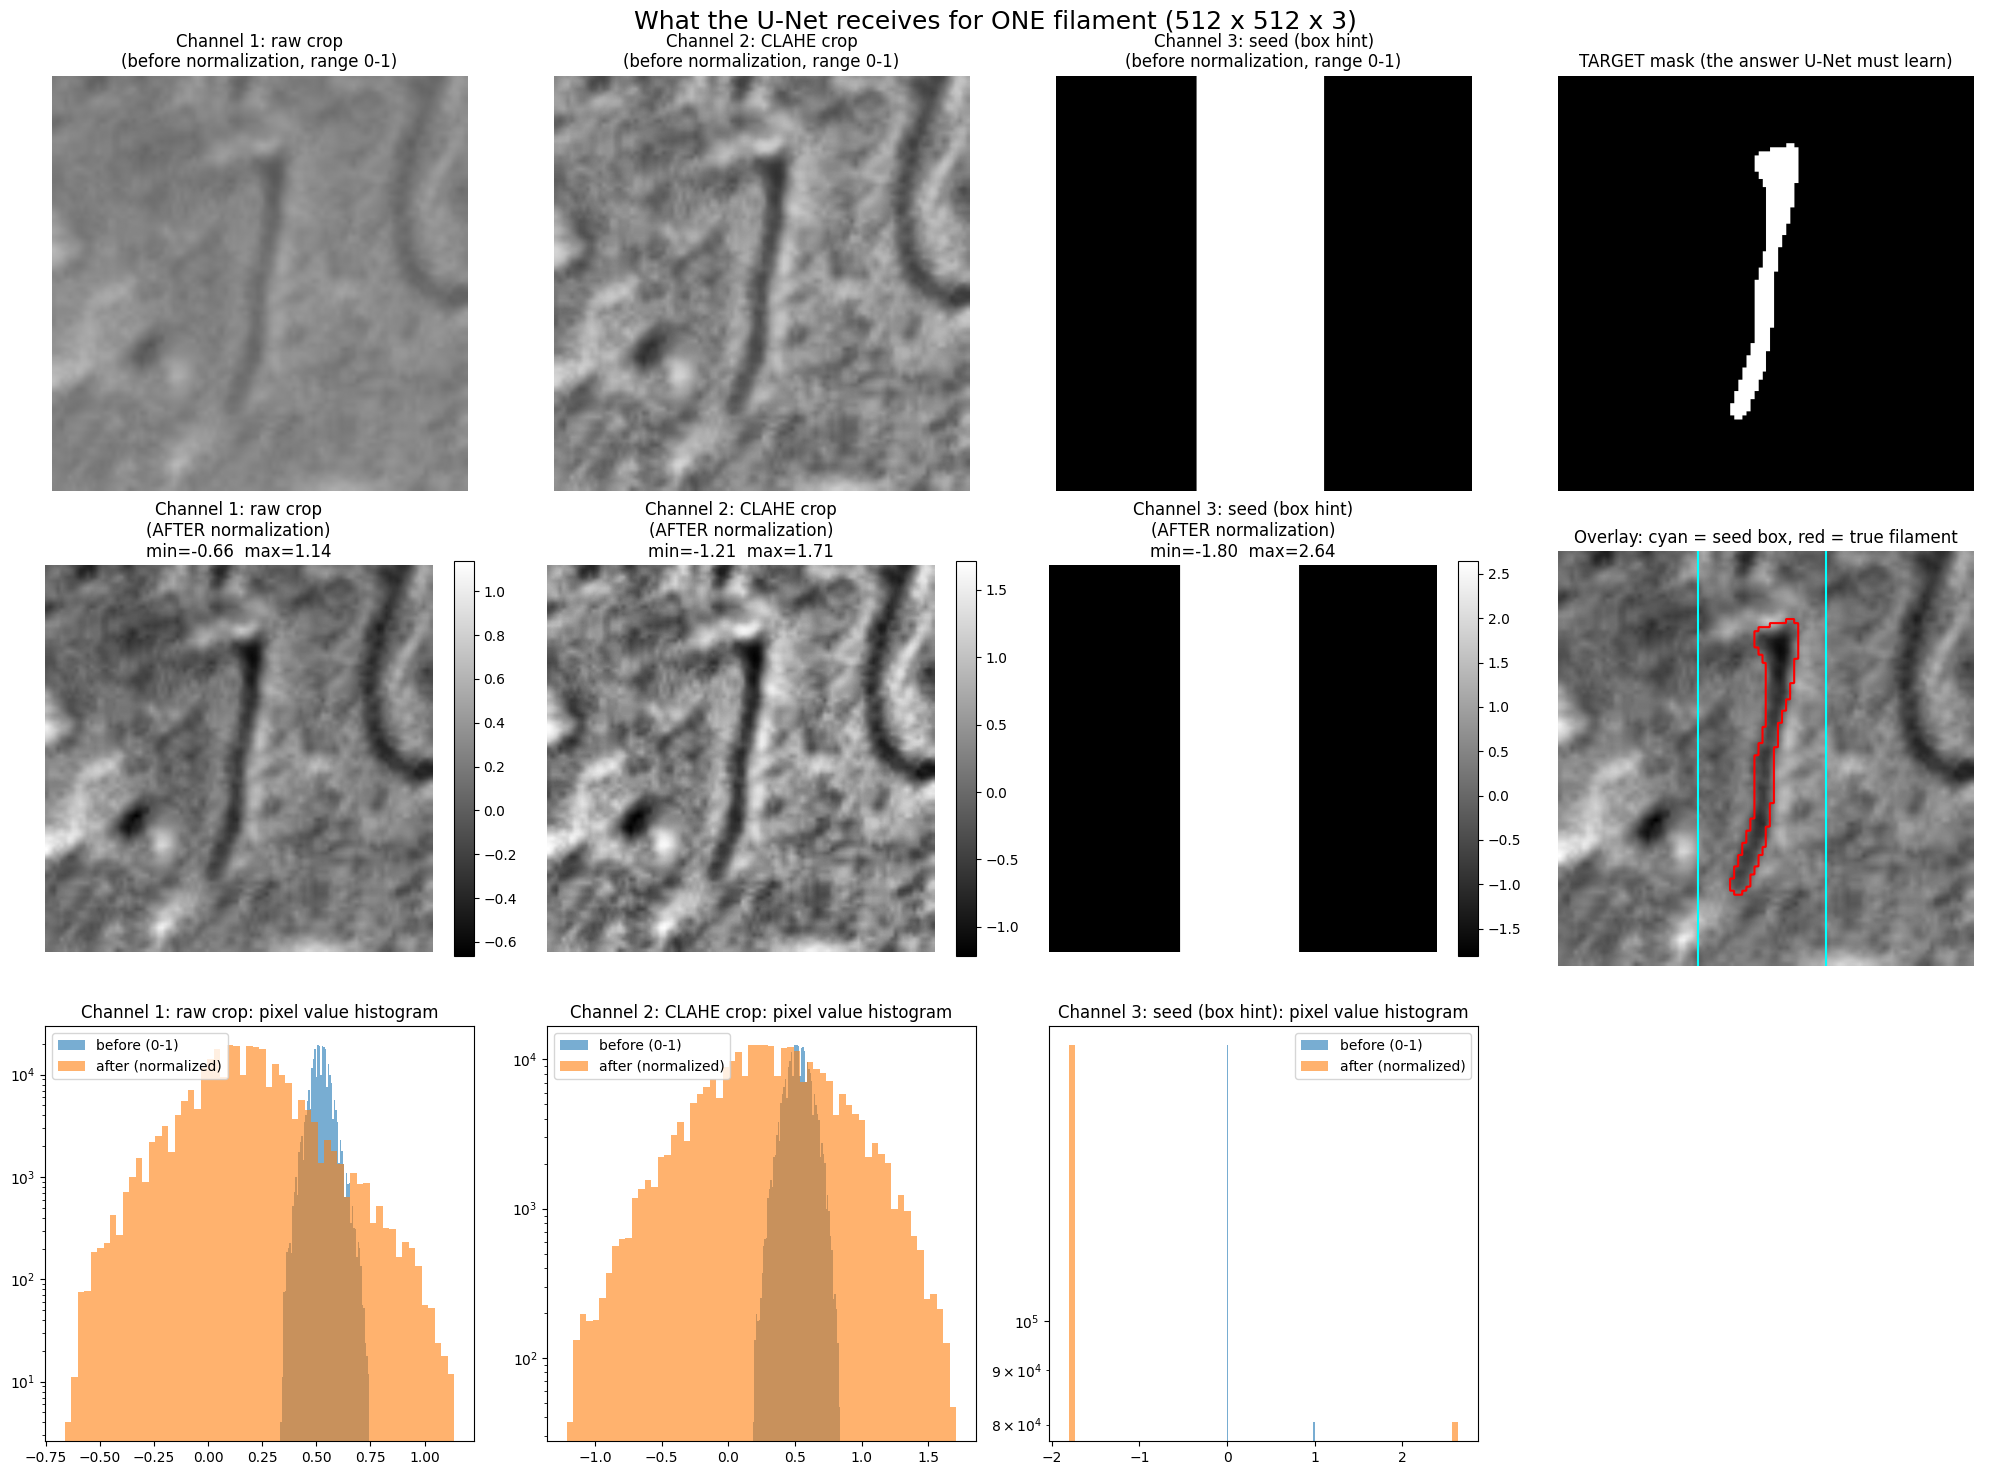

Input tensor shape : (3, 512, 512) (channels, height, width)
Target shape       : (512, 512)

Channel 1: raw crop              before: min=0.33 max=0.75 mean=0.52 | after: min=-0.66 max=1.14 mean=0.16
Channel 2: CLAHE crop            before: min=0.18 max=0.84 mean=0.53 | after: min=-1.21 max=1.71 mean=0.31
Channel 3: seed (box hint)       before: min=0.00 max=1.00 mean=0.31 | after: min=-1.80 max=2.64 mean=-0.44


In [3]:
# ====================================================================
# VISUALIZE WHAT THE U-NET RECEIVES (one filament)
# Paste as a new cell AFTER Block 2 (needs val_ds, REFINE_CROP).
# Change SAMPLE_IDX to look at a different filament.
# ====================================================================
import numpy as np
import matplotlib.pyplot as plt

SAMPLE_IDX = 5   # try 0, 10, 50, 100 ...

# val_ds has augment=False, so no random flips/jitter: clean example
x_norm, y = val_ds[SAMPLE_IDX]
x_norm = x_norm.numpy()          # (3, 512, 512)  NORMALIZED input
target = y.numpy()[0]            # (512, 512)     answer mask

# Undo normalization to recover the 0-1 images (for display only)
mean = np.array([0.485, 0.456, 0.406], np.float32)[:, None, None]
std  = np.array([0.229, 0.224, 0.225], np.float32)[:, None, None]
x_raw01 = x_norm * std + mean    # back to 0-1

names = ["Channel 1: raw crop", "Channel 2: CLAHE crop", "Channel 3: seed (box hint)"]

fig, axes = plt.subplots(3, 4, figsize=(20, 15))

# ---- Row 1: the 3 channels BEFORE normalization (0-1) + target ----
for c in range(3):
    axes[0, c].imshow(x_raw01[c], cmap="gray", vmin=0, vmax=1)
    axes[0, c].set_title(f"{names[c]}\n(before normalization, range 0-1)")
axes[0, 3].imshow(target, cmap="gray")
axes[0, 3].set_title("TARGET mask (the answer U-Net must learn)")

# ---- Row 2: the 3 channels AFTER normalization ----
for c in range(3):
    im = axes[1, c].imshow(x_norm[c], cmap="gray")
    axes[1, c].set_title(f"{names[c]}\n(AFTER normalization)\n"
                         f"min={x_norm[c].min():.2f}  max={x_norm[c].max():.2f}")
    plt.colorbar(im, ax=axes[1, c], fraction=0.046)

# overlay: raw crop + seed box + true filament outline
axes[1, 3].imshow(x_raw01[0], cmap="gray")
axes[1, 3].contour(x_raw01[2] > 0.5, levels=[0.5], colors="cyan", linewidths=1.5)
axes[1, 3].contour(target > 0.5, levels=[0.5], colors="red", linewidths=1.5)
axes[1, 3].set_title("Overlay: cyan = seed box, red = true filament")

# ---- Row 3: histograms before vs after normalization ----
for c in range(3):
    axes[2, c].hist(x_raw01[c].ravel(), bins=60, alpha=0.6, label="before (0-1)")
    axes[2, c].hist(x_norm[c].ravel(),  bins=60, alpha=0.6, label="after (normalized)")
    axes[2, c].set_yscale("log")
    axes[2, c].set_title(f"{names[c]}: pixel value histogram")
    axes[2, c].legend()
axes[2, 3].axis("off")

for r in range(2):
    for c in range(4):
        axes[r, c].axis("off")

plt.suptitle("What the U-Net receives for ONE filament (512 x 512 x 3)", fontsize=18)
plt.tight_layout()
plt.show()

# ---- Numbers to quote ----
print("Input tensor shape :", x_norm.shape, "(channels, height, width)")
print("Target shape       :", target.shape)
print()
for c in range(3):
    print(f"{names[c]:32s} before: min={x_raw01[c].min():.2f} max={x_raw01[c].max():.2f} "
          f"mean={x_raw01[c].mean():.2f} | after: min={x_norm[c].min():.2f} "
          f"max={x_norm[c].max():.2f} mean={x_norm[c].mean():.2f}")

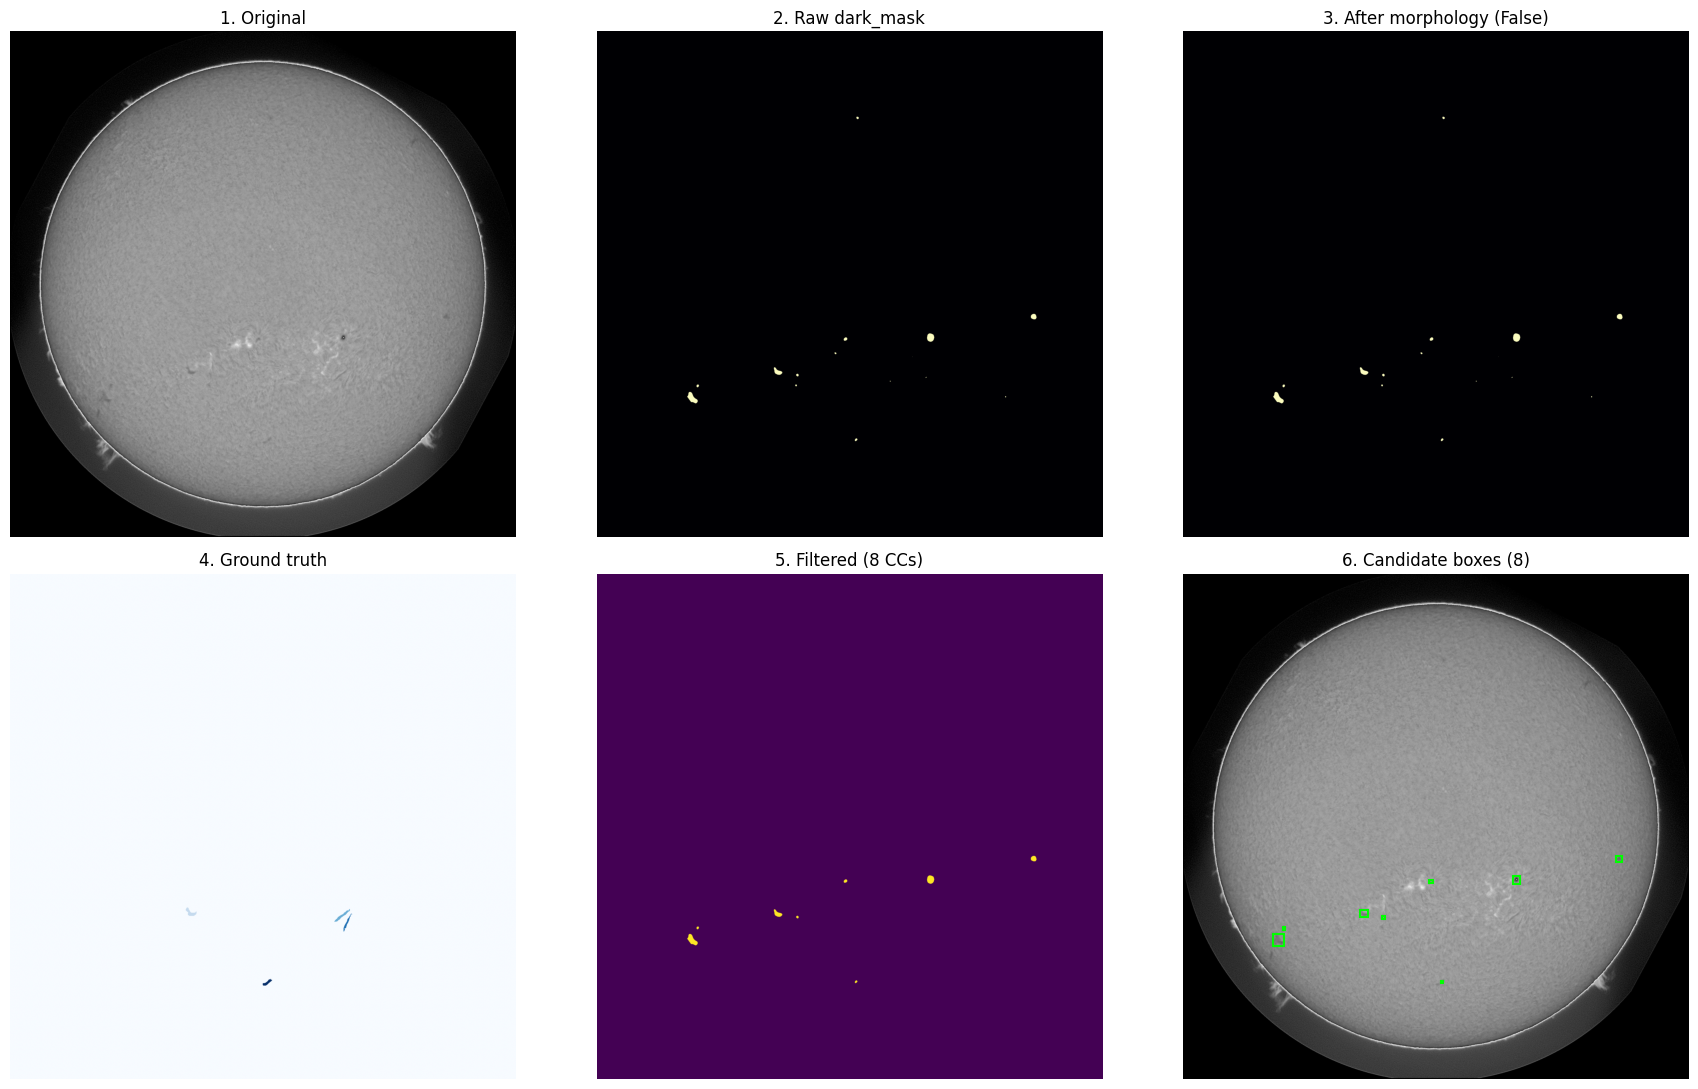

raw=15  small_removed=7  large_removed=0  retained=8


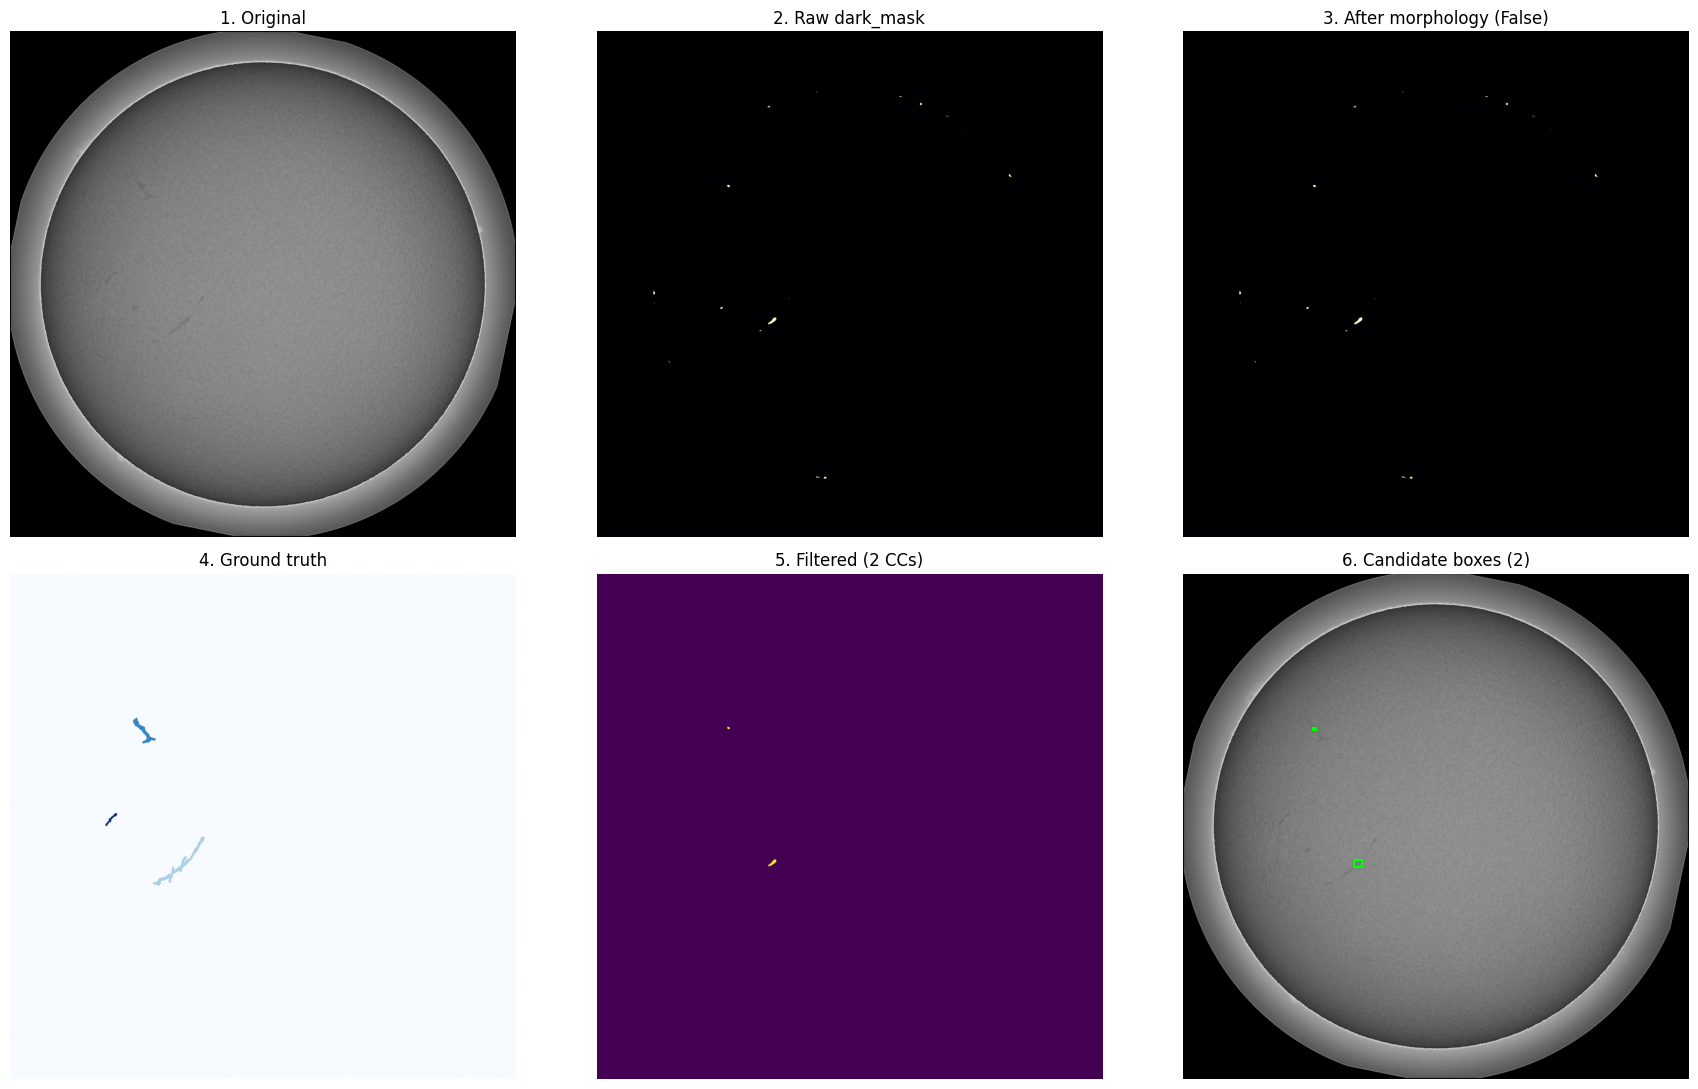

raw=19  small_removed=17  large_removed=0  retained=2


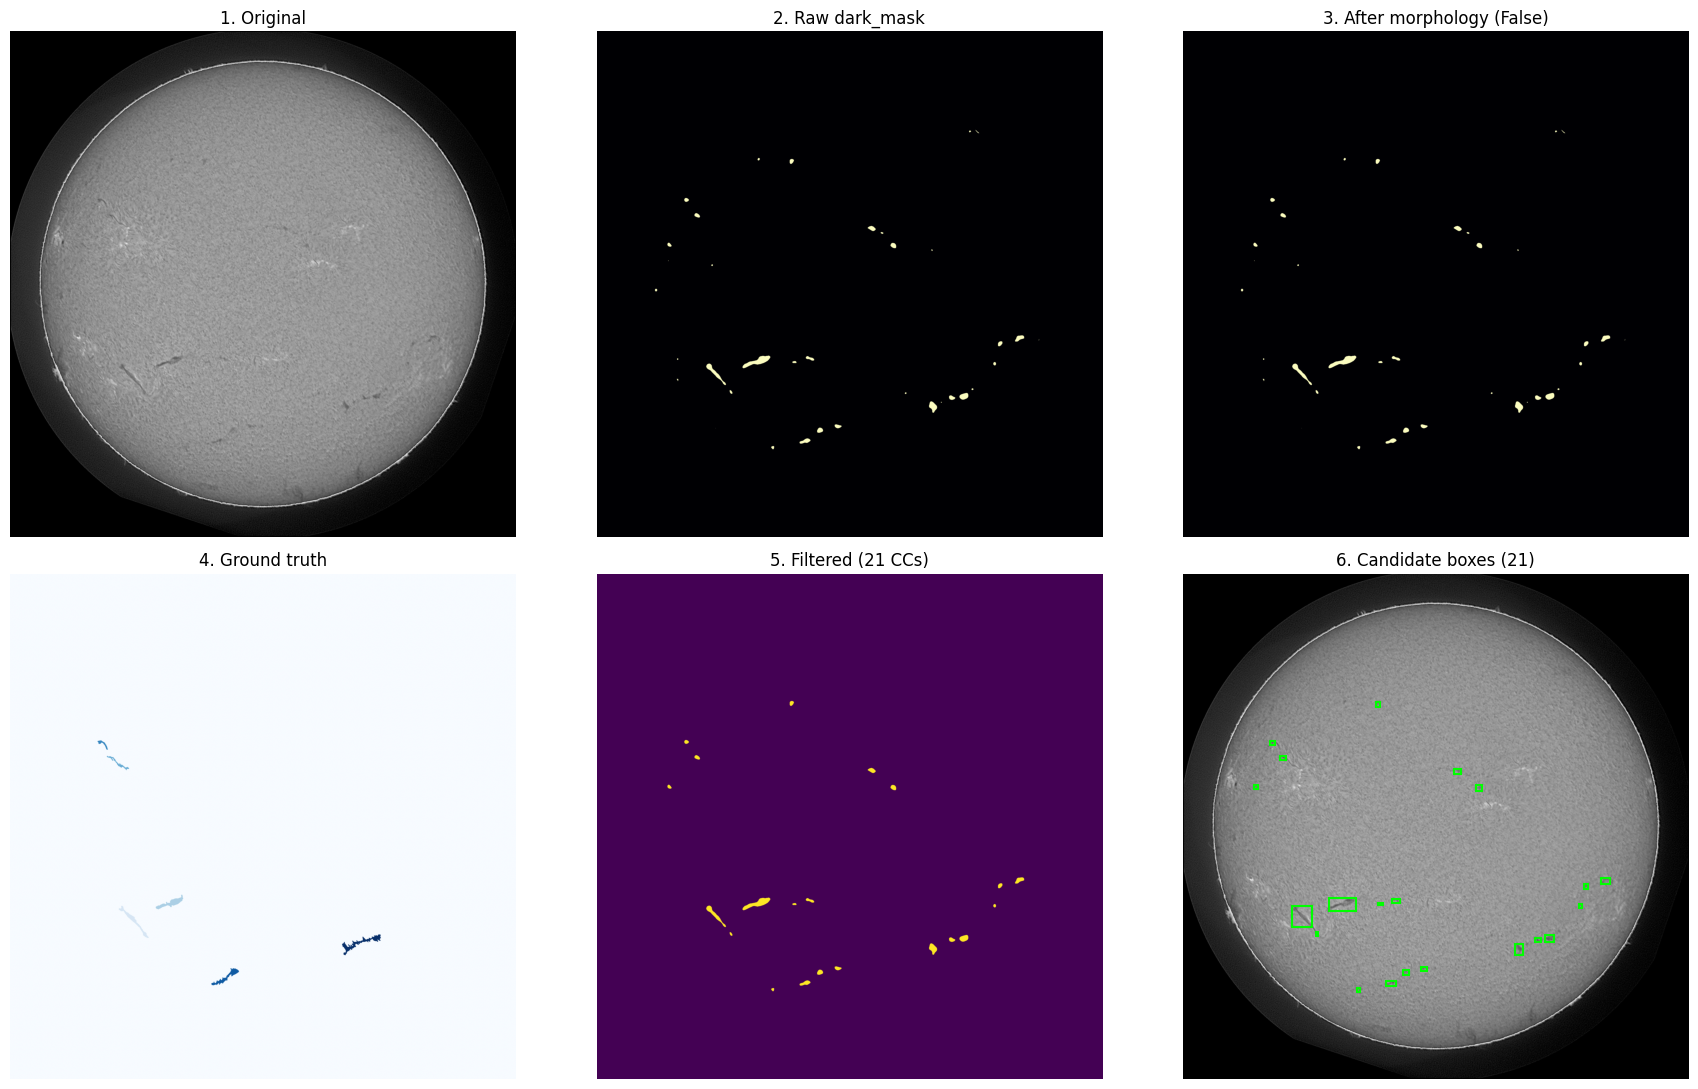

raw=36  small_removed=15  large_removed=0  retained=21
STEP 1: QUICK SCORE CHECK ON TRAIN IMAGES (sanity check)
20201228202430Ch.jpeg               pred=  8 gt=  4 dice=0.215 pq=0.251
20180306081810Th.jpeg               pred=  2 gt=  3 dice=0.313 pq=0.000
20121108155954Bh.jpeg               pred= 21 gt=  6 dice=0.241 pq=0.144
20110119082634Lh.jpeg               pred= 11 gt=  5 dice=0.334 pq=0.163
20111226155454Bh.jpeg               pred= 18 gt=  4 dice=0.180 pq=0.175
20170728150230Ch.jpeg               pred= 10 gt=  5 dice=0.376 pq=0.258
20120427063154Uh.jpeg               pred= 29 gt= 10 dice=0.168 pq=0.059
20220617185352Mh.jpeg               pred= 58 gt=  4 dice=0.029 pq=0.000
20121118092514Th.jpeg               pred= 27 gt= 17 dice=0.387 pq=0.201
20131017185334Ch.jpeg               pred= 29 gt= 13 dice=0.264 pq=0.141
20110410141654Bh.jpeg               pred= 13 gt=  4 dice=0.263 pq=0.110
20170809164910Mh.jpeg               pred= 17 gt=  3 dice=0.100 pq=0.000
20130107174854Bh.jpeg   

Predicting:   0%|          | 0/180 [00:00<?, ?it/s]


DONE
Total predicted filaments : 3959
Images with errors        : 0
Written to                : /kaggle/working/submission.csv
           filament_id                                   segmentation_rle
0   20110120105534Ch_1  WZfW11no15TPNNbo12]PN0bo10^PN1ao1M`PN5_o16cPNB...
1   20110120105534Ch_2  o_^i24lo1101O010O00001VPNMdo18000004MN10O00101...
2   20110120105534Ch_3  ^e`Z12mo13M3L3N3N0O2O001001N100O1O100O1O1NNH]P...
3   20110120105534Ch_4  lihQ23jo13N100O101O00OK7M2J60O1000N2K4O2O1O3M2...
4   20110120105534Ch_5  bkhm11no13O0O000N2O1O00000001O0001N102N1O2OO10...
5   20110120105534Ch_6  [Zoj25io12N3M3O001N1O1O002O0N2O101O001N110ODiP...
6   20110120105534Ch_7  d]cX31no1;F3M2N2M2O1O1N2O0ODlPNNRo1a0O100O0010...
7   20110120105534Ch_8  ^`[o27io11HLaPN7]o17O1O6J001N1O01J5000O2O1000N...
8   20110120105534Ch_9  baeR31lo15M2N0O2O011O0100O0000O2N2K4M4N01010O0...
9  20110120105534Ch_10  VbkP35ko13M9G2\OC_QNb0^n1@]QNe0bn1>0O0O1_O_QNA...


In [4]:
"""
====================================================================
FINAL CELL (Person 3): Person 1 + Person 2's real code
          -> U-Net refinement -> score check -> submission.csv
====================================================================

WHERE TO PASTE THIS:
One new cell at the very end of your ORIGINAL notebook -- run AFTER
the cells that:
  - load libraries, find image/annotation paths
  - build + load your trained U-Net refiner
  - define refine_box_on_image(), mask_to_rle(), MIN_AREA, test_paths

Do NOT run the YOLO det_model.predict cells -- not needed, this cell
replaces that detection step entirely with Person 1 + Person 2's work.

Person 1's part1() and Person 2's run_person2_pipeline() are included
below EXACTLY as delivered -- nothing about their logic was changed.
====================================================================
"""

import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

try:
    from pycocotools import mask as mask_utils
except Exception:
    mask_utils = None

# ====================================================================
# PERSON 1 -- solar disk detection + dark-region mask (as delivered)
# ====================================================================

WORK_SIZE         = 512
R_MIN_FRAC        = 0.30
R_MAX_FRAC        = 0.50
DISK_SHRINK       = 0.97
ANALYSIS_SHRINK   = 0.88      # tuned
FLAT_SIGMA_FRAC   = 0.05
SMOOTH_SIGMA_FRAC = 0.003
CONTRAST_T        = 0.95      # tuned

def _circle_mask(shape, cx, cy, r):
    m = np.zeros(shape, np.uint8)
    cv2.circle(m, (int(round(cx)), int(round(cy))), int(round(r)), 1, -1)
    return m.astype(bool)

def detect_limb(gray):
    h, w = gray.shape
    s = WORK_SIZE / max(h, w)
    small = cv2.resize(gray, (int(round(w * s)), int(round(h * s))), interpolation=cv2.INTER_AREA)
    small = cv2.GaussianBlur(small, (0, 0), 2)
    m = min(small.shape)
    circles = cv2.HoughCircles(small, cv2.HOUGH_GRADIENT, dp=1, minDist=m,
                               param1=80, param2=25,
                               minRadius=int(R_MIN_FRAC * m), maxRadius=int(R_MAX_FRAC * m))
    if circles is not None:
        cx, cy, r = circles[0][0] / s
        if np.hypot(cx - w / 2, cy - h / 2) / min(h, w) < 0.10:
            return cx, cy, r, "hough"
    warnings.warn("Hough failed - using blob fallback")
    _, rough = cv2.threshold(gray, 5, 255, cv2.THRESH_BINARY)
    n, _, stats, cents = cv2.connectedComponentsWithStats(rough, connectivity=8)
    if n <= 1:
        return w / 2, h / 2, 0.44 * min(h, w), "default"
    k = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    return cents[k][0], cents[k][1], float(np.sqrt(stats[k, cv2.CC_STAT_AREA] / np.pi)), "blob"

def flatten(gray_f, disk):
    h, w = gray_f.shape
    s = 0.25
    g = cv2.resize(gray_f, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    d = cv2.resize(disk.astype(np.float32), None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    sig = FLAT_SIGMA_FRAC * min(g.shape)
    bg = cv2.GaussianBlur(g * d, (0, 0), sig) / np.maximum(cv2.GaussianBlur(d, (0, 0), sig), 1e-3)
    bg = cv2.resize(bg, (w, h), interpolation=cv2.INTER_LINEAR)
    return np.where(disk, gray_f / np.maximum(bg, 1.0), 1.0).astype(np.float32)

def part1(gray):
    h, w = gray.shape
    cx, cy, r, method = detect_limb(gray)
    disk_mask = _circle_mask(gray.shape, cx, cy, r * DISK_SHRINK)
    analysis  = _circle_mask(gray.shape, cx, cy, r * ANALYSIS_SHRINK)

    sigma  = max(SMOOTH_SIGMA_FRAC * min(h, w), 0.5)
    ratio  = flatten(cv2.GaussianBlur(gray.astype(np.float32), (0, 0), sigma), disk_mask)

    v = np.clip(ratio[analysis] * 128, 0, 255).astype(np.uint8).reshape(-1, 1)
    t, _ = cv2.threshold(v, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    otsu_val  = t / 128.0
    otsu_mask = (ratio < otsu_val) & analysis
    dark_mask = (ratio < CONTRAST_T) & analysis

    return dict(cx=cx, cy=cy, r=r, method=method, disk_mask=disk_mask, analysis=analysis,
                ratio=ratio, otsu_val=otsu_val, otsu_mask=otsu_mask, dark_mask=dark_mask)

def load_gray(p):
    return cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)


# ====================================================================
# PERSON 2 -- connected components + area filtering (exactly as delivered)
# ====================================================================

MIN_FIL_AREA       = 80              # Absolute minimum pixel count to filter point noise
MAX_AREA_FRAC      = 0.01            # Max component area as fraction of solar disk area
USE_MORPHOLOGY     = False           # kept False by default -- protects thin barbs
MORPH_KERNEL_SIZE  = 3

def run_person2_pipeline(dark_mask, disk_mask, apply_morph=USE_MORPHOLOGY):
    """
    Person 2's delivered function, unchanged:
    dark_mask -> optional morphology -> 8-connectivity CC -> area filtering -> bboxes
    """
    mask = dark_mask.astype(np.uint8) * 255

    if apply_morph:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (MORPH_KERNEL_SIZE, MORPH_KERNEL_SIZE))
        mask_clean = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    else:
        mask_clean = mask.copy()

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        (mask_clean > 0).astype(np.uint8), connectivity=8
    )

    disk_area = disk_mask.sum()
    max_area = MAX_AREA_FRAC * disk_area

    filtered_mask = np.zeros_like(mask_clean, dtype=bool)
    bboxes = []
    small_removed = large_removed = retained_count = 0

    for label_id in range(1, num_labels):
        area = stats[label_id, cv2.CC_STAT_AREA]
        if area < MIN_FIL_AREA:
            small_removed += 1
            continue
        if area > max_area:
            large_removed += 1
            continue
        retained_count += 1
        comp_pixels = (labels == label_id)
        filtered_mask[comp_pixels] = True

        x = stats[label_id, cv2.CC_STAT_LEFT]
        y = stats[label_id, cv2.CC_STAT_TOP]
        w = stats[label_id, cv2.CC_STAT_WIDTH]
        h = stats[label_id, cv2.CC_STAT_HEIGHT]
        bboxes.append((x, y, x + w, y + h))

    stats_dict = {
        "raw_components": num_labels - 1, "retained": retained_count,
        "small_removed": small_removed, "large_removed": large_removed,
        "max_area_cutoff": int(max_area),
    }
    return filtered_mask, bboxes, stats_dict, mask_clean

def visualize_person2(image_path, gt_mask_arr=None):
    g = load_gray(image_path)
    R = part1(g)
    filtered_mask, bboxes, report, morph_mask = run_person2_pipeline(R["dark_mask"], R["disk_mask"])

    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    axes[0, 0].imshow(g, cmap="gray"); axes[0, 0].set_title("1. Original")
    axes[0, 1].imshow(R["dark_mask"], cmap="magma"); axes[0, 1].set_title("2. Raw dark_mask")
    axes[0, 2].imshow(morph_mask, cmap="magma"); axes[0, 2].set_title(f"3. After morphology ({USE_MORPHOLOGY})")
    if gt_mask_arr is not None:
        axes[1, 0].imshow(gt_mask_arr, cmap="Blues")
    axes[1, 0].set_title("4. Ground truth")
    axes[1, 1].imshow(filtered_mask, cmap="viridis"); axes[1, 1].set_title(f"5. Filtered ({report['retained']} CCs)")
    axes[1, 2].imshow(g, cmap="gray")
    for (x1, y1, x2, y2) in bboxes:
        axes[1, 2].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=1.5))
    axes[1, 2].set_title(f"6. Candidate boxes ({len(bboxes)})")
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    print(f"raw={report['raw_components']}  small_removed={report['small_removed']}  "
          f"large_removed={report['large_removed']}  retained={report['retained']}")
    return report
# ====================================================================
# PERSON 3 -- run through YOUR existing U-Net refiner
# Depends on refine_box_on_image(), MIN_AREA, mask_to_rle() already
# being defined earlier in this same notebook.
# ====================================================================

PAD_PX = 10  # Person 2's bboxes are tight to the component; pad before refining

def run_classical_pipeline(image_path):
    gray = load_gray(image_path)
    h, w = gray.shape
    R = part1(gray)
    _, bboxes, _, _ = run_person2_pipeline(R["dark_mask"], R["disk_mask"])

    scored = []
    for x1, y1, x2, y2 in bboxes:
        px1 = max(0, x1 - PAD_PX)
        py1 = max(0, y1 - PAD_PX)
        px2 = min(w, x2 + PAD_PX)
        py2 = min(h, y2 + PAD_PX)
        mask, score = refine_box_on_image(gray, [px1, py1, px2, py2], 1.0)
        if int(mask.sum()) >= MIN_AREA:
            scored.append((score, mask))

    # THIS is the missing step -- guarantees no two masks share a pixel
    return resolve_overlapping_masks(scored)   # already defined in your notebook (section 29)

def predict_image_to_rows_classical(image_path):
    image_id = Path(image_path).stem
    masks = run_classical_pipeline(image_path)
    return [
        {"filament_id": f"{image_id}_{i}", "segmentation_rle": mask_to_rle(m)}  # from your notebook
        for i, m in enumerate(masks, start=1)
    ]


# ====================================================================
# PERSON 4 -- quick score check before submitting (Dice + PQ)
# ====================================================================

def _ann_mask(ann, h, w):
    seg = ann.get("segmentation")
    if seg and mask_utils is not None:
        try:
            rles = mask_utils.frPyObjects(seg, h, w)
            rle = mask_utils.merge(rles) if isinstance(rles, list) else rles
            m = mask_utils.decode(rle)
            return (m.any(axis=2) if m.ndim == 3 else m).astype(np.uint8)
        except Exception:
            pass
    m = np.zeros((h, w), np.uint8)
    if seg and isinstance(seg, list):
        for poly in seg:
            pts = np.array(poly, np.float32).reshape(-1, 2).round().astype(np.int32)
            cv2.fillPoly(m, [pts], 1)
    return m

def dice_score(pred_mask, gt_mask_arr):
    inter = np.logical_and(pred_mask, gt_mask_arr).sum()
    total = pred_mask.sum() + gt_mask_arr.sum()
    return 1.0 if total == 0 else 2.0 * inter / total

def iou_score(pred_mask, gt_mask_arr):
    inter = np.logical_and(pred_mask, gt_mask_arr).sum()
    union = np.logical_or(pred_mask, gt_mask_arr).sum()
    return 0.0 if union == 0 else inter / union

def panoptic_quality(pred_masks, gt_masks, iou_thresh=0.5):
    if len(gt_masks) == 0 and len(pred_masks) == 0:
        return 1.0, 0, 0, 0
    if len(gt_masks) == 0:
        return 0.0, 0, len(pred_masks), 0
    if len(pred_masks) == 0:
        return 0.0, 0, 0, len(gt_masks)
    iou_matrix = np.zeros((len(pred_masks), len(gt_masks)))
    for i, pm in enumerate(pred_masks):
        for j, gm in enumerate(gt_masks):
            iou_matrix[i, j] = iou_score(pm, gm)
    matched_pred, matched_gt, pairs = set(), set(), []
    flat_idx = np.dstack(np.unravel_index(np.argsort(-iou_matrix, axis=None), iou_matrix.shape))[0]
    for i, j in flat_idx:
        if iou_matrix[i, j] <= iou_thresh:
            break
        if i in matched_pred or j in matched_gt:
            continue
        matched_pred.add(i); matched_gt.add(j); pairs.append(iou_matrix[i, j])
    tp, fp, fn = len(pairs), len(pred_masks) - len(pairs), len(gt_masks) - len(pairs)
    pq = 0.0 if tp == 0 else sum(pairs) / (tp + 0.5 * fp + 0.5 * fn)
    return pq, tp, fp, fn

def quick_score_check(n_images=15):
    # Build gt_by_name from what your notebook actually defines
    gt_by_name = {
        images_by_id[image_id]["file_name"]: anns
        for image_id, anns in anns_by_image.items()
    }

    scoreable = [p for p in Path(TRAIN_IMAGES).iterdir() if p.name in gt_by_name]
    sample = scoreable[:n_images]

    rows = []
    for p in sample:
        gray = load_gray(p)
        h, w = gray.shape
        gt_masks = [_ann_mask(a, h, w).astype(bool) for a in gt_by_name[p.name]]
        pred_masks = run_classical_pipeline(p)

        mean_dice = 0.0
        if pred_masks and gt_masks:
            mean_dice = float(np.mean([max(dice_score(pm, gm) for gm in gt_masks) for pm in pred_masks]))
        pq, tp, fp, fn = panoptic_quality(pred_masks, gt_masks)

        rows.append(dict(image=p.name, n_pred=len(pred_masks), n_gt=len(gt_masks),
                          dice=round(mean_dice, 3), pq=round(pq, 3)))
        print(f"{p.name:35s} pred={len(pred_masks):3d} gt={len(gt_masks):3d} "
              f"dice={mean_dice:.3f} pq={pq:.3f}")

    df = pd.DataFrame(rows)
    print(f"\nMean Dice: {df['dice'].mean():.3f}   Mean PQ: {df['pq'].mean():.3f}")
    return df

# lookup: file name -> its annotations
gt_by_name = {images_by_id[i]["file_name"]: a for i, a in anns_by_image.items()}

def get_gt_mask(image_path):
    p = Path(image_path)
    gray = load_gray(p)
    h, w = gray.shape
    gt = np.zeros((h, w), np.uint8)
    for k, ann in enumerate(gt_by_name.get(p.name, []), start=1):
        gt[_ann_mask(ann, h, w).astype(bool)] = k   # each filament gets its own number
    return gt

# use it

# ====================================================================
# RUN EVERYTHING
# ====================================================================
sample_images = list(Path(TRAIN_IMAGES).iterdir())[:3]
for img_path in sample_images:
    visualize_person2(img_path, gt_mask_arr=get_gt_mask(img_path))
print("=" * 70)
print("STEP 1: QUICK SCORE CHECK ON TRAIN IMAGES (sanity check)")
print("=" * 70)
quick_score_check(n_images=15)

print()
print("=" * 70)
print("STEP 2: GENERATING submission.csv ON TEST SET")
print("=" * 70)
print(f"Test images: {len(test_paths)}")   # test_paths from your notebook

all_rows, errors = [], []
for p in tqdm(test_paths, desc="Predicting"):
    try:
        all_rows.extend(predict_image_to_rows_classical(p))
    except Exception as e:
        errors.append((p.name, str(e)))
        print(f"  ERROR on {p.name}: {e}")

submission_df = pd.DataFrame(all_rows, columns=["filament_id", "segmentation_rle"])
OUT_PATH = "/kaggle/working/submission.csv"
submission_df.to_csv(OUT_PATH, index=False)

print()
print("DONE")
print(f"Total predicted filaments : {len(submission_df)}")
print(f"Images with errors        : {len(errors)}")
print(f"Written to                : {OUT_PATH}")
print(submission_df.head(10))